# T-learner, S-learner and causal forest: cross-fitted CATE vs placebo

Three ways of estimating the CATE of aspirin are compared:

- **T-learner**: two risk models, one fitted on the patients who received aspirin and one on those who did not. The CATE is the predicted risk under treatment minus the predicted risk without it.
- **S-learner**: a single risk model with the treatment among its features. The CATE is its prediction with the treatment set to 1 minus its prediction with the treatment set to 0.
- **Causal forest**: a forest whose trees group similar patients and compare treated and control outcomes within each group, so it estimates the CATE directly.

The T-learner and S-learner are each run with three base classifiers (logistic regression, random forest, gradient boosting).

Each patient's CATE is predicted by a model fitted on the other folds (5-fold cross-fitting), so no patient is scored by a model that saw them.

As a reference, the logistic T-learner is also run with the treatment labels randomly permuted across patients (placebo): any heterogeneity it finds is estimation noise. The question is whether the true CATE shows more structure than the placebo, judged on the uplift-by-decile curve. The test set is not used.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

from ml_med.modeling import (
    cross_fit_cate,
    prepare_data,
    split_train_test,
    uplift_by_decile,
)

FEATURES_PATH = Path("../data/processed/ist_features.parquet")

In [2]:
df = pd.read_parquet(FEATURES_PATH)
X, y, t = prepare_data(df, "RXASP")
X_train, X_test, y_train, y_test, t_train, t_test = split_train_test(X, y, t)

In [3]:
candidates = {
    "logistic": None,
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, random_state=0, n_jobs=-1
    ),
    "gradient_boosting": HistGradientBoostingClassifier(random_state=0),
}

In [4]:
cates = {}

t_placebo = t_train.sample(frac=1, random_state=0).set_axis(t_train.index)
cates["placebo"] = cross_fit_cate(X_train, y_train, t_placebo, "RXASP")

for learner in ("t", "s"):
    for name, clf in candidates.items():
        cates[f"{learner}_{name}"] = cross_fit_cate(
            X_train, y_train, t_train, "RXASP", clf=clf, learner=learner
        )

cates["causal_forest"] = cross_fit_cate(
    X_train, y_train, t_train, "RXASP", learner="cf"
)
pd.DataFrame({name: c.describe() for name, c in cates.items()}).round(3)

,placebo,t_logistic,t_random_forest,t_gradient_boosting,s_logistic,s_random_forest,s_gradient_boosting,causal_forest
count,15428.000,15428.000,15428.000,15428.000,15428.000,15428.000,15428.000,15428.000
mean,-0.003,-0.012,-0.014,-0.013,-0.013,-0.004,-0.006,-0.013
std,0.052,0.050,0.047,0.133,0.006,0.009,0.020,0.014
min,-0.348,-0.356,-0.203,-0.731,-0.022,-0.045,-0.143,-0.064
25%,-0.029,-0.041,-0.045,-0.085,-0.019,-0.009,-0.013,-0.023
50%,-0.001,-0.013,-0.012,-0.006,-0.013,-0.003,-0.001,-0.013
75%,0.025,0.013,0.018,0.057,-0.007,0.002,0.001,-0.003
max,0.483,0.332,0.184,0.622,-0.000,0.029,0.313,0.033


In [5]:
uplifts = {}
uplifts["placebo"] = uplift_by_decile(cates["placebo"], y_train, t_placebo)

for name, cate in cates.items():
    t = t_placebo if name == "placebo" else t_train
    uplifts[name] = uplift_by_decile(cate, y_train, t)

pd.DataFrame({name: u["uplift"] for name, u in uplifts.items()}).round(3)

,placebo,t_logistic,t_random_forest,t_gradient_boosting,s_logistic,s_random_forest,s_gradient_boosting,causal_forest
decile,,,,,,,,
1,-0.004,0.016,-0.006,0.011,-0.011,0.017,-0.006,-0.026
2,-0.027,-0.037,0.018,-0.068,0.029,-0.015,0.003,0.007
3,0.009,-0.032,-0.006,0.008,0.017,-0.043,-0.016,-0.024
4,0.029,-0.040,-0.024,-0.010,-0.017,-0.008,0.032,-0.015
5,-0.002,-0.012,-0.012,0.009,-0.031,-0.006,-0.057,-0.040
6,0.016,-0.031,-0.021,-0.017,-0.031,-0.011,-0.033,-0.002
7,-0.010,-0.009,-0.015,0.012,-0.056,-0.016,-0.032,-0.009
8,0.018,0.001,-0.022,-0.019,-0.036,-0.000,0.013,0.010
9,-0.019,-0.005,-0.008,-0.029,0.021,0.010,-0.035,-0.011


In [9]:
uplifts["causal_forest"].round(3)

,n,cate_mean,rate_control,rate_treated,uplift
decile,,,,,
1,1543,-0.037,0.448,0.422,-0.026
2,1543,-0.028,0.461,0.468,0.007
3,1543,-0.023,0.517,0.493,-0.024
4,1542,-0.019,0.586,0.571,-0.015
5,1543,-0.015,0.633,0.594,-0.040
6,1543,-0.011,0.665,0.663,-0.002
7,1542,-0.008,0.713,0.705,-0.009
8,1543,-0.003,0.721,0.731,0.010
9,1543,0.001,0.788,0.777,-0.011


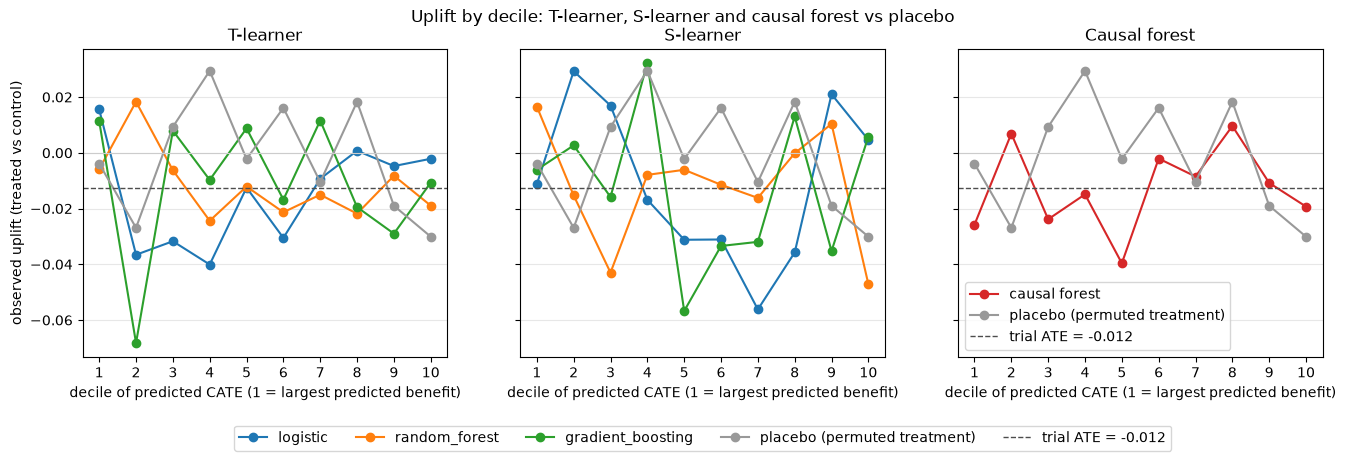

In [8]:
ate = y_train[t_train == 1].mean() - y_train[t_train == 0].mean()
colors = {
    "logistic": "tab:blue",
    "random_forest": "tab:orange",
    "gradient_boosting": "tab:green",
}
titles = {"t": "T-learner", "s": "S-learner", "cf": "Causal forest"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, learner in zip(axes, ("t", "s", "cf")):
    if learner == "cf":
        u = uplifts["causal_forest"]
        ax.plot(
            u.index, u["uplift"], marker="o", color="tab:red", label="causal forest"
        )
    else:
        for clf_name, color in colors.items():
            u = uplifts[f"{learner}_{clf_name}"]
            ax.plot(u.index, u["uplift"], marker="o", color=color, label=clf_name)
    u = uplifts["placebo"]
    ax.plot(
        u.index,
        u["uplift"],
        marker="o",
        color="0.6",
        label="placebo (permuted treatment)",
    )
    ax.axhline(
        ate, linestyle="--", color="0.3", linewidth=1, label=f"trial ATE = {ate:.3f}"
    )
    ax.axhline(0, color="0.8", linewidth=0.8)
    ax.set_xticks(u.index)
    ax.set_xlabel("decile of predicted CATE (1 = largest predicted benefit)")
    ax.set_title(titles[learner])
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("observed uplift (treated vs control)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=5)
axes[2].legend(loc="best")
fig.suptitle("Uplift by decile: T-learner, S-learner and causal forest vs placebo")
plt.show()

## Conclusions

1. The T-learner recovers the average effect. The mean cross-fitted CATE is
−0.012, the same as the trial ATE (observed outcome rate in treated minus
controls). As an estimator of the average effect, the T-learner works.

2. The individual CATE is estimation noise. The spread of the predicted CATE
(std ≈ 0.05) is the same with the true treatment and with a permuted one, and
the uplift-by-decile curve is indistinguishable from the placebo curve: it
bounces around the ATE with the same amplitude, and decile 1, where the model
promises the largest benefit, shows no benefit at all. A single placebo is one
draw of noise; a bootstrap band (later) will make this comparison sharper.

3. The predicted CATE tracks baseline risk, not response. Control-arm outcome
rates are highest in the middle deciles. The difference of two logistic
predictions is mechanically largest where risk is near 0.5, so a T-learner on
the probability scale "finds" heterogeneity for a geometric reason, not a
clinical one.

4. The verdict does not depend on the base classifier. Random forest and
gradient boosting give uplift curves as flat as the logistic one. The
gradient-boosting T-learner is instructive: its predicted CATE spans ±0.7
(std 0.13, almost three times the others) yet its uplift curve is no steeper.
The spread of the predicted CATE measures how much the two arm models
disagree, and an overfitting learner disagrees more; it is not a measure of
heterogeneity.

5. S-learner: narrow spread, same flat curve. The S-learner predicts a much narrower CATE distribution (std 0.006 to 0.020 vs 0.05 to 0.13 for the T-learner), but its uplift-by-decile curve is as flat as the others.

6. Verdict after six learners. Neither meta-learner, with any of the three base classifiers, finds a CATE ordering that beats a permuted treatment. The next candidate is a method built for this problem, the causal forest.

7. Causal forest: modest claims, same flat curve. The causal forest recovers the ATE (mean cross-fitted CATE −0.013) with a narrow, plausible spread (std 0.014). Its uplift-by-decile curve bounces around the ATE with the same amplitude as the placebo, so it does not demonstrate heterogeneity. Unlike the T-learner it is not refuted either: predicted and observed uplift differ by less than one decile standard error (≈ 0.036) in every decile. The forest orders patients by baseline risk (control-arm outcome rate rises from 0.45 in decile 1 to 0.82 in decile 10), suggesting a larger benefit in milder strokes; the data point that way (uplift ≈ −0.020 in deciles 1–5 vs ≈ −0.006 in deciles 6–10) but the difference is within noise. The metre is too coarse to confirm or reject effects this small.

